In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [4]:
ds = pd.read_csv("concrete_data.csv")
ds.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
ds.shape

(1030, 9)

In [6]:
ds.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [7]:
ds.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [8]:
X = ds.drop(columns=["Strength"])
y = ds.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [9]:
Lr = LinearRegression()
Lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[0.12,0.11,0.08,...,0.02,0.02,0.12]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Cement','Blast Furnace Slag','Fly Ash',...,'Coarse Aggregate', 'Fine Aggregate','Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-28.82
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,8


In [10]:
y_pred = Lr.predict(X_test)

r2_score(y_test,y_pred)

0.627553179231485

In [21]:
lr = LinearRegression()
np.mean(cross_val_score(lr,X,y,scoring="r2"))

np.float64(0.46099404916628606)

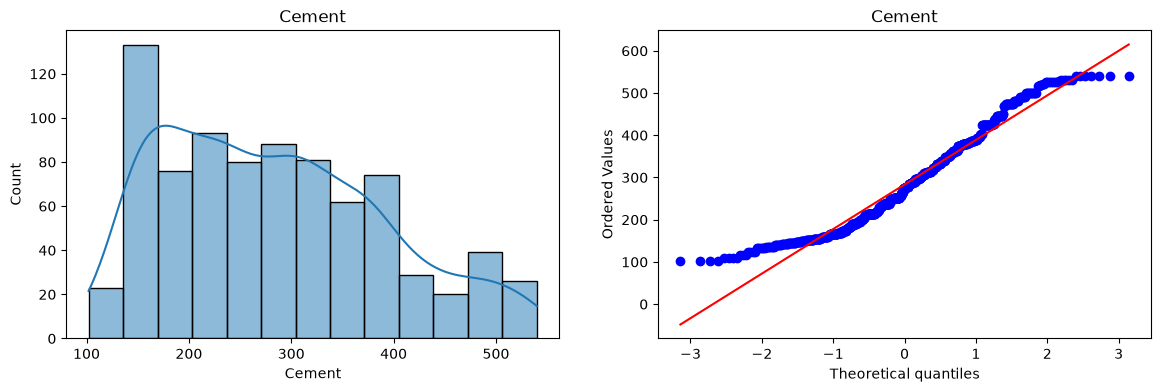

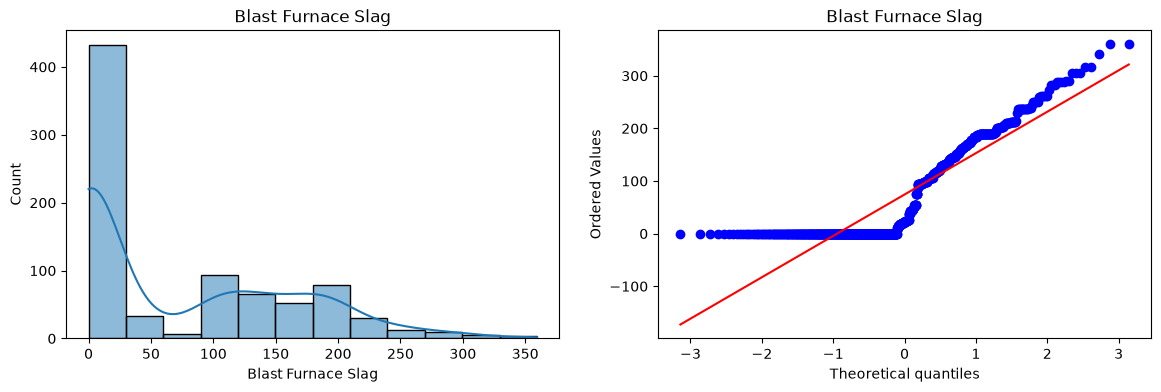

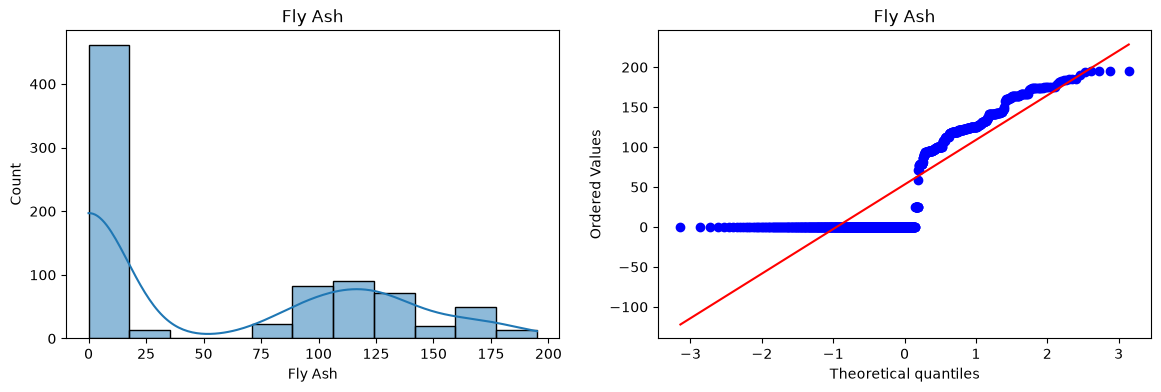

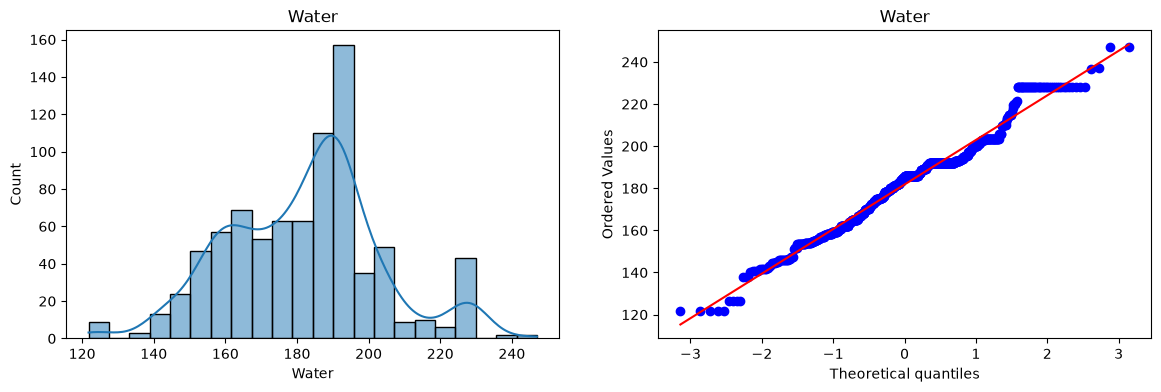

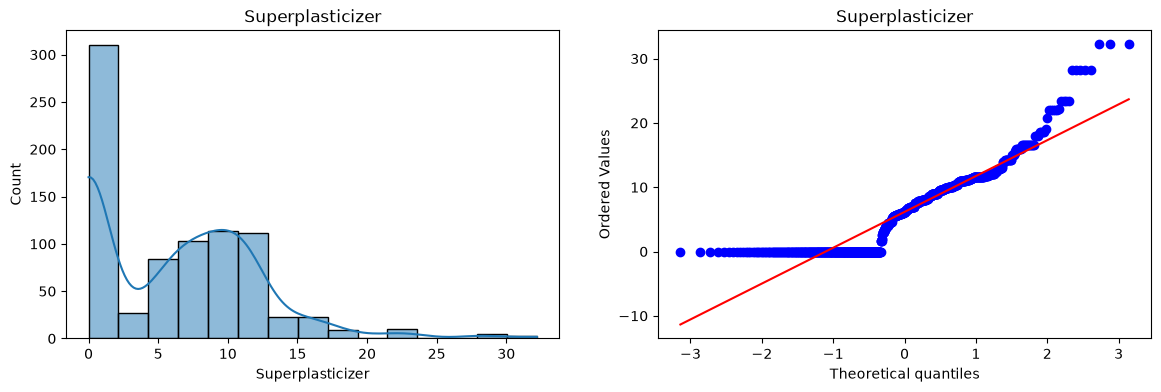

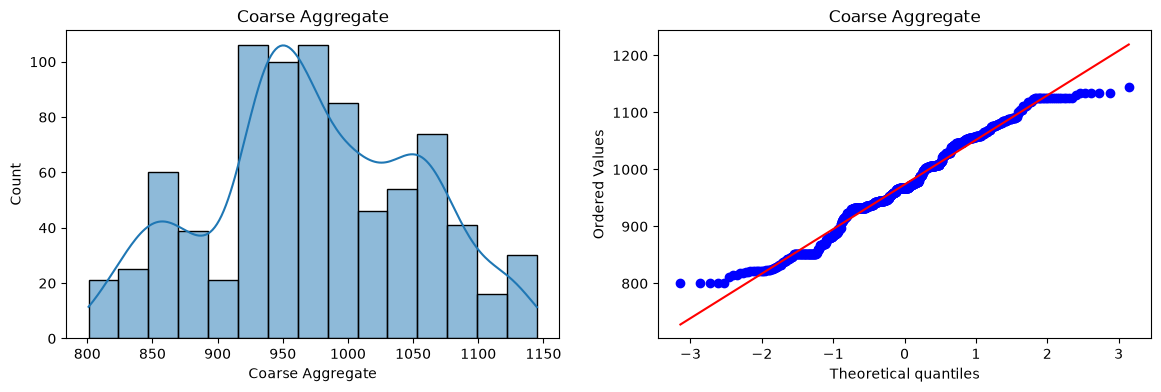

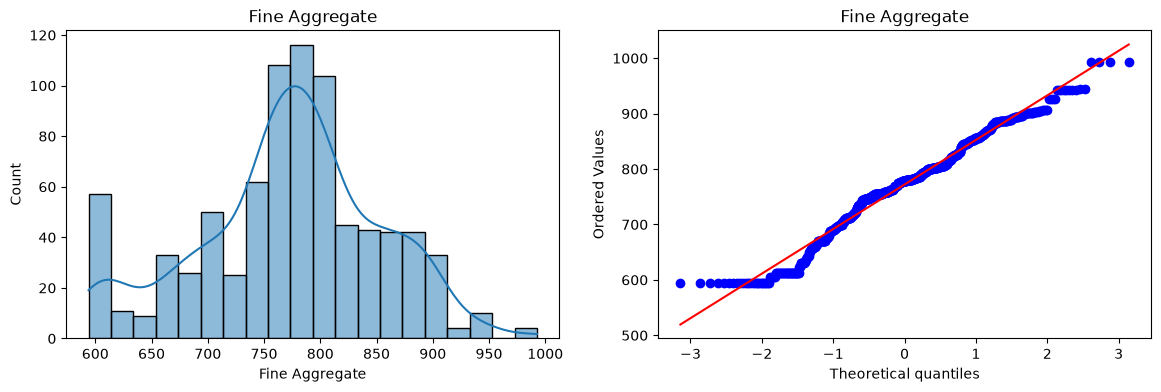

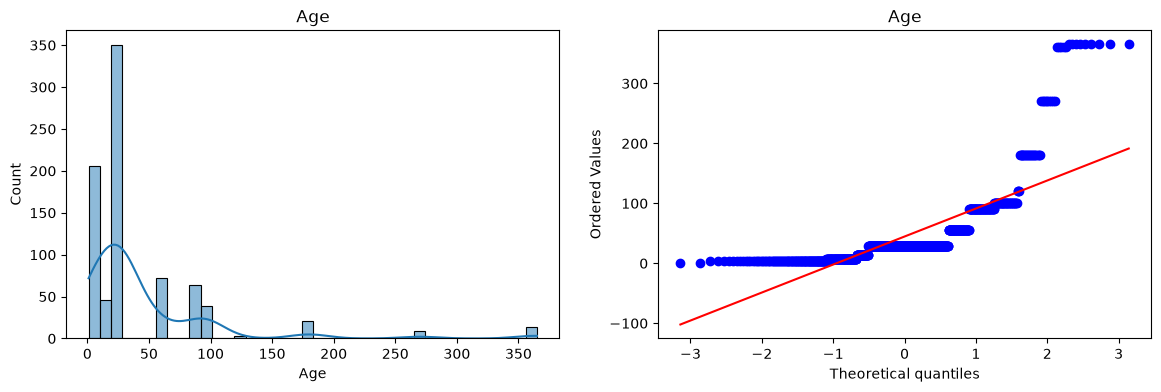

In [13]:
for col in X_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col],kde=True)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(X_train[col], dist="norm",plot=plt)
    plt.title(col)

    plt.show()

In [22]:
pt = PowerTransformer(method="box-cox")

X_train_transformed = pt.fit_transform(X_train+0.0000000001)
X_test_transformed = pt.transform(X_test+0.0000000001)
X_train_transformed_ds = pd.DataFrame(X_train_transformed,columns=X_train.columns)

pd.DataFrame({"col":X_train.columns, "box_cox_lambda": pt.lambdas_})

,col,box_cox_lambda
0,Cement,0.177025
1,Blast Furnace Slag,0.017671
2,Fly Ash,-0.025976
3,Water,0.772682
4,Superplasticizer,0.064135
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [20]:
pt = PowerTransformer(method="box-cox")
lr = LinearRegression()
X_transformed = pt.fit_transform(X+0.0000001)
cv = 5
np.mean(cross_val_score(lr,X_transformed,y,cv=cv,scoring="r2"))

np.float64(0.6658537935432477)

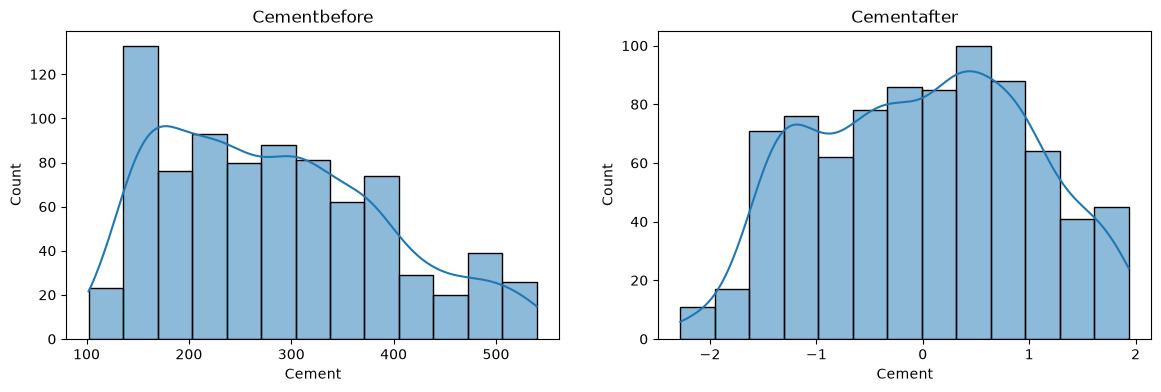

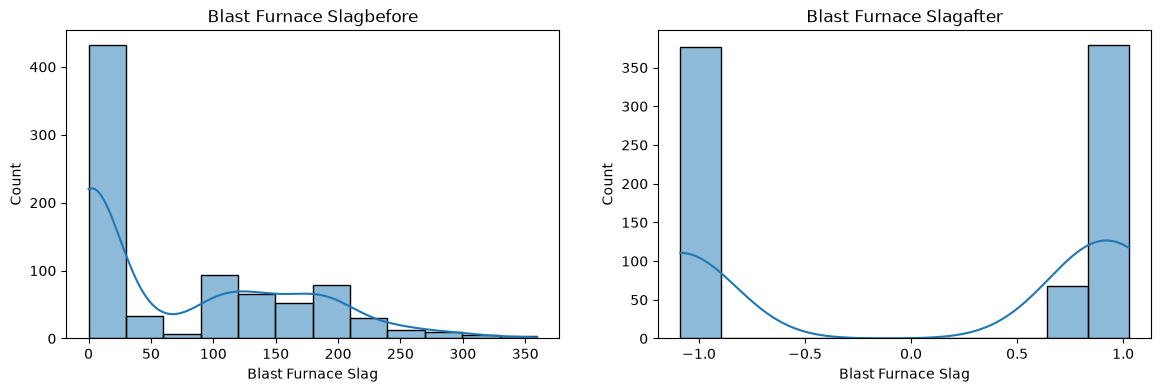

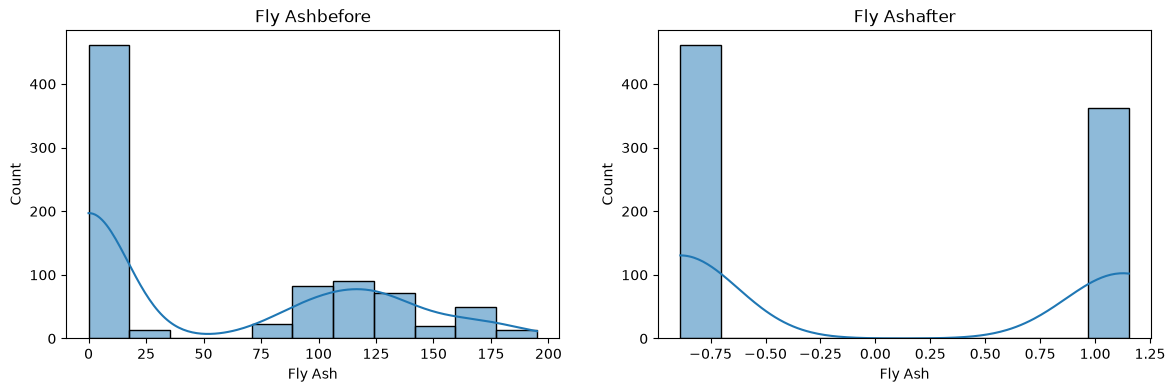

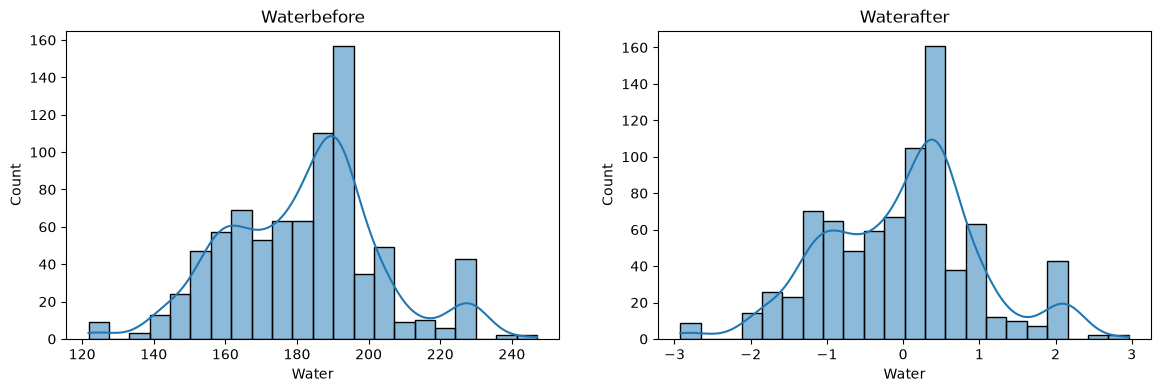

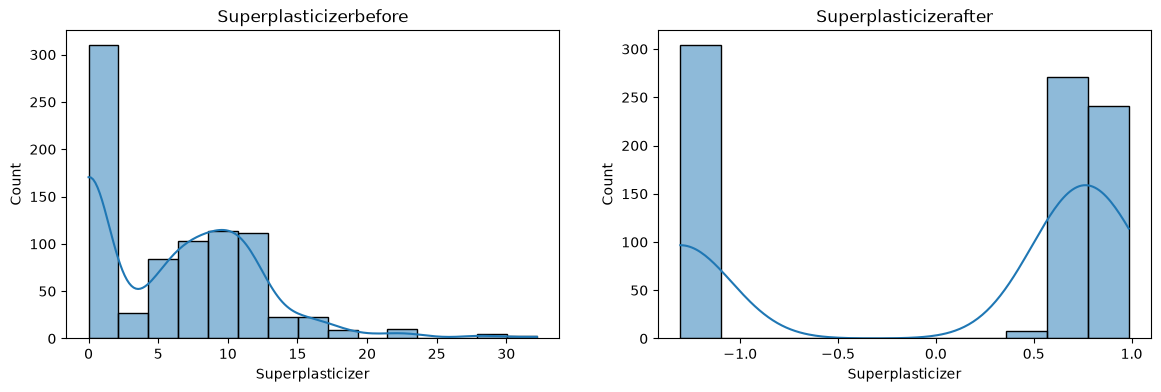

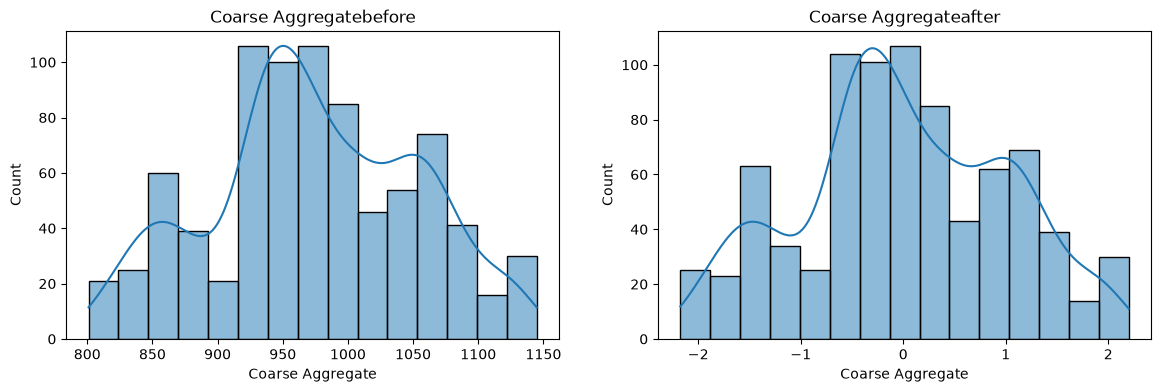

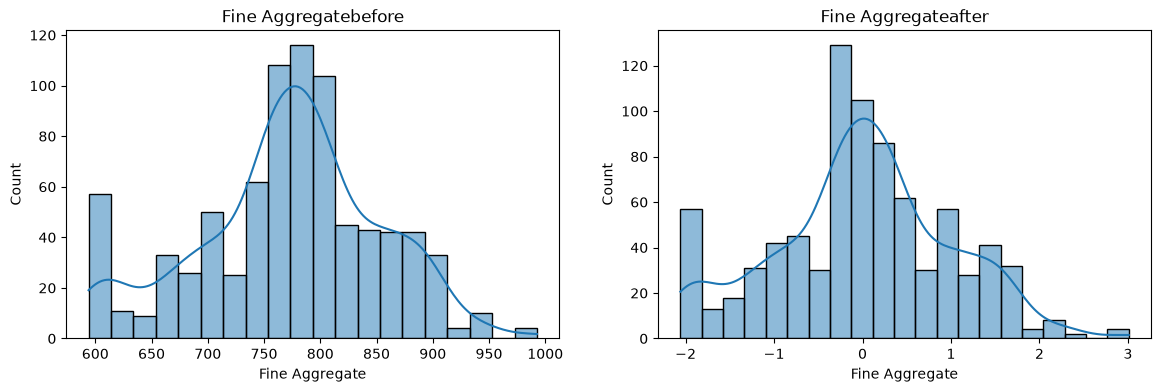

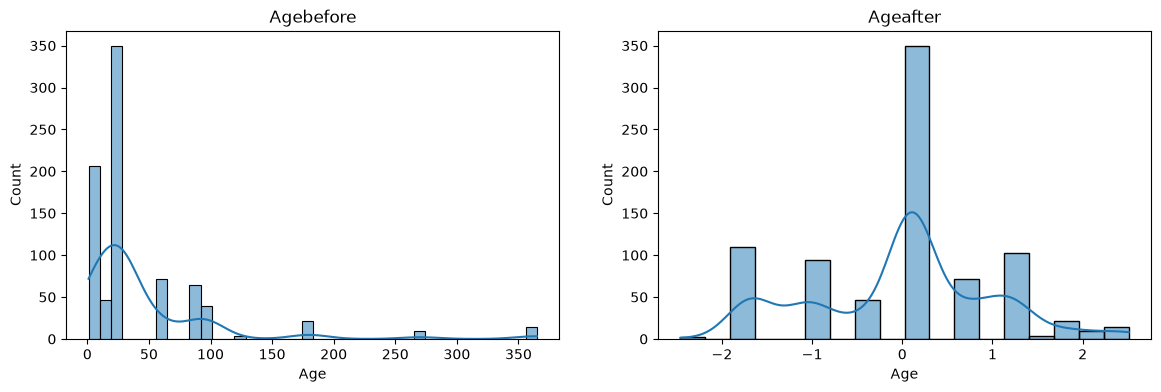

In [24]:
for col in X_train_transformed_ds.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col],kde=True)
    plt.title(col+"before")
    
    plt.subplot(122)
    sns.histplot(X_train_transformed_ds[col],kde=True)
    plt.title(col+"after")

    plt.show()

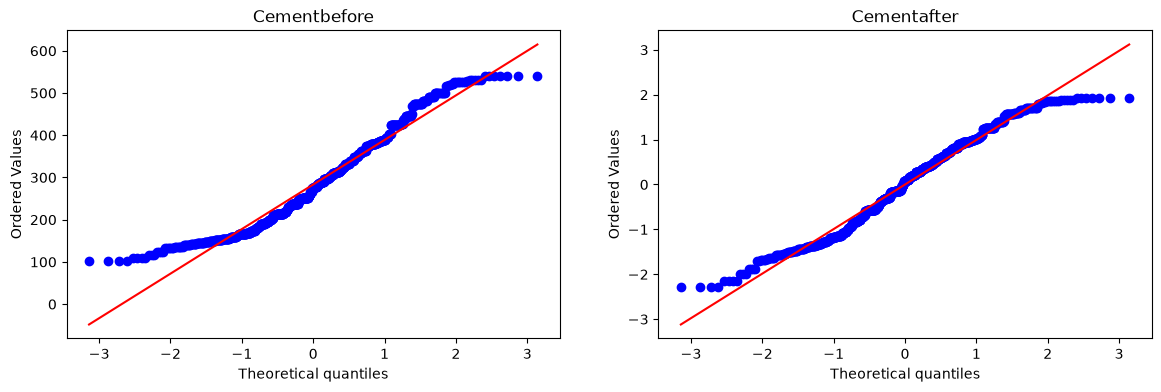

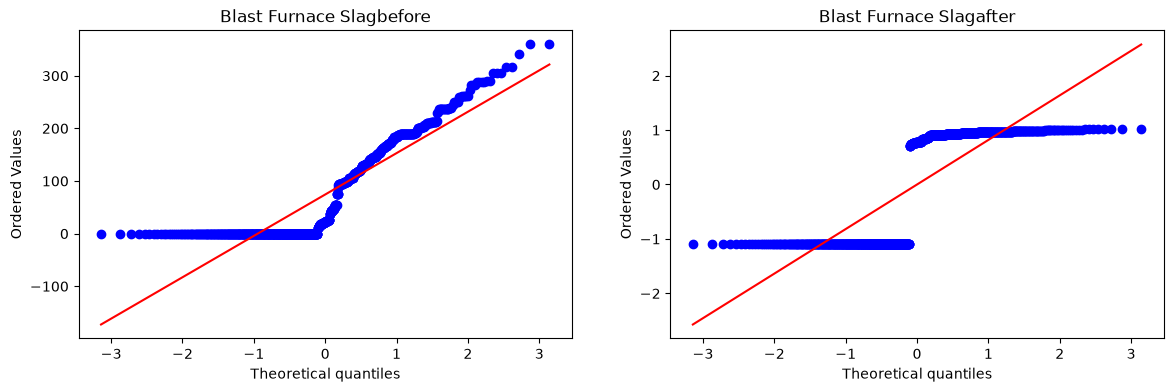

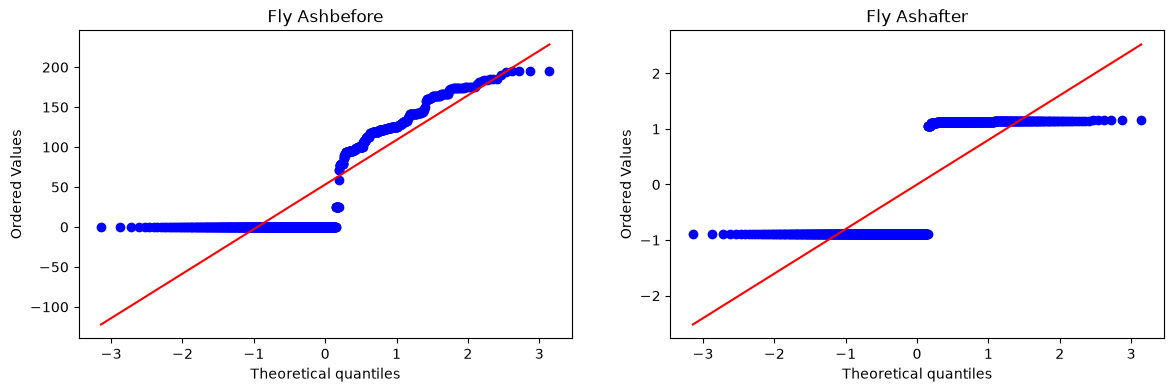

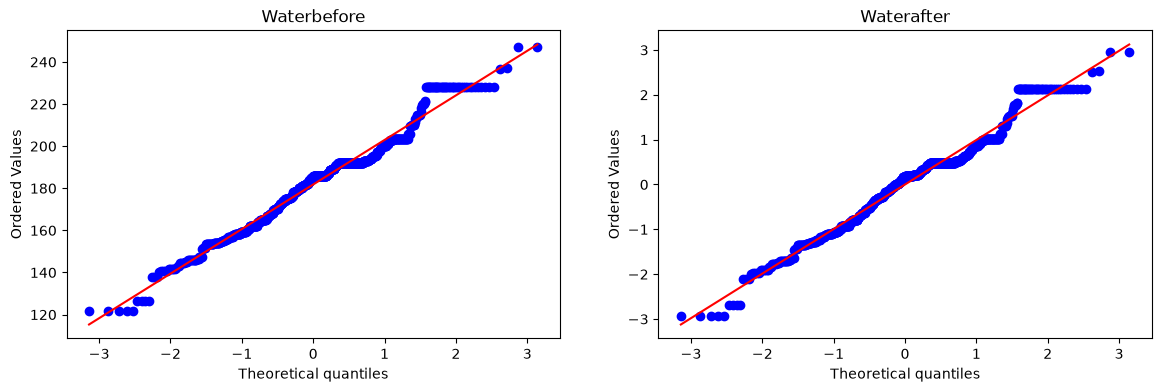

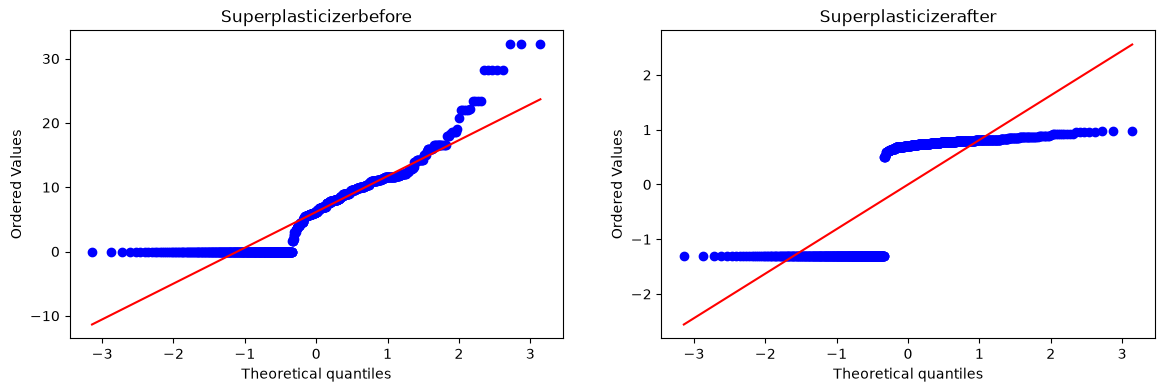

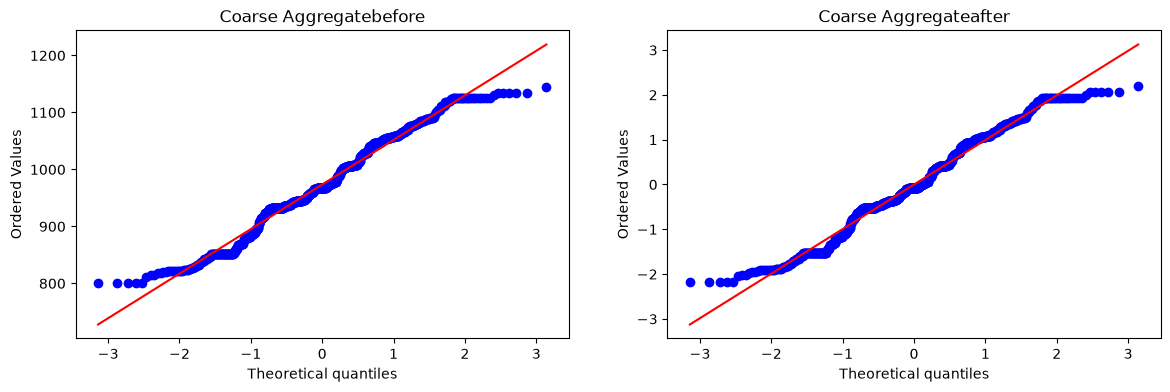

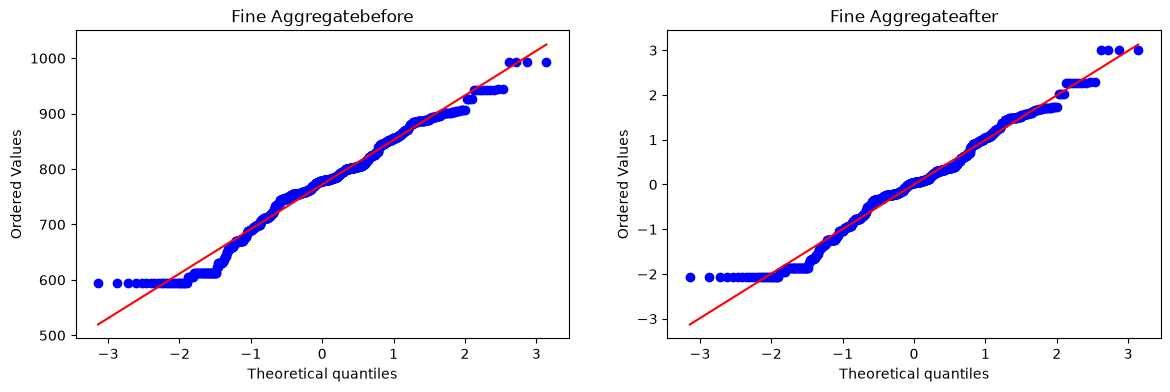

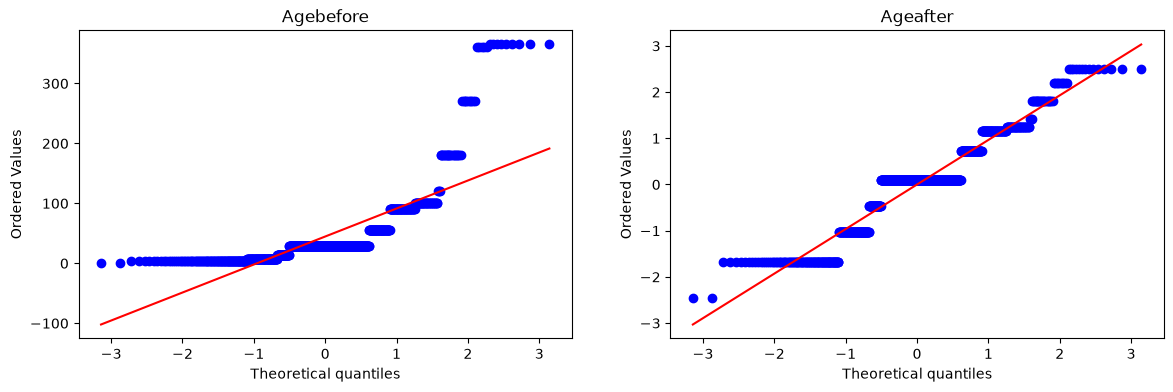

In [25]:
for col in X_train_transformed_ds.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    stats.probplot(X_train[col], dist="norm",plot=plt)
    plt.title(col+"before")
    
    plt.subplot(122)
    stats.probplot(X_train_transformed_ds[col], dist="norm",plot=plt)
    plt.title(col+"after")

    plt.show()

In [31]:
pt1 = PowerTransformer()

X_train_transformed1 = pt1.fit_transform(X_train)
X_test_transformed1 = pt1.transform(X_test)

X_train_transformed_ds2 = pd.DataFrame(X_train_transformed1,columns=X_train.columns)
pd.DataFrame({"Col": X_train.columns,"lambda Function":pt1.lambdas_})

,Col,lambda Function
0,Cement,0.174348
1,Blast Furnace Slag,0.015715
2,Fly Ash,-0.161447
3,Water,0.771307
4,Superplasticizer,0.253935
5,Coarse Aggregate,1.130050
6,Fine Aggregate,1.783100
7,Age,0.019885


In [32]:
pt1 = PowerTransformer()
X_trm = pt1.fit_transform(X)
lr=LinearRegression()
np.mean(cross_val_score(lr,X_trm,y,scoring="r2"))

np.float64(0.6834625131982249)

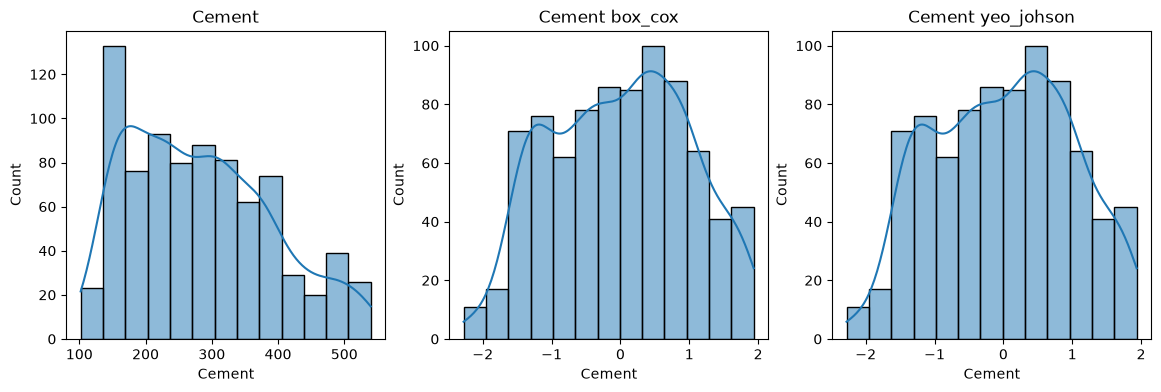

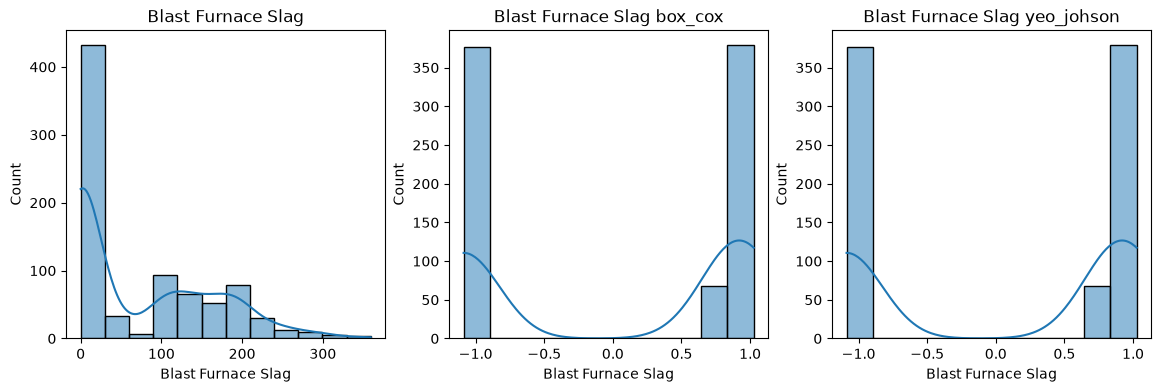

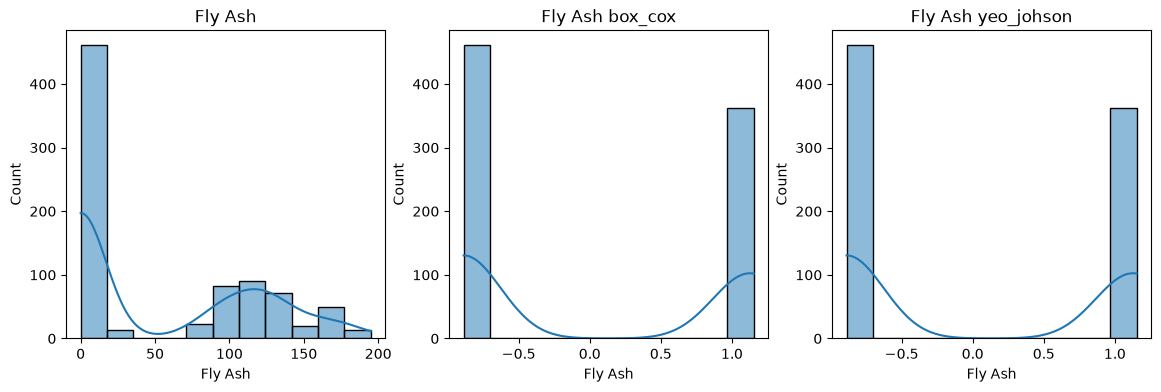

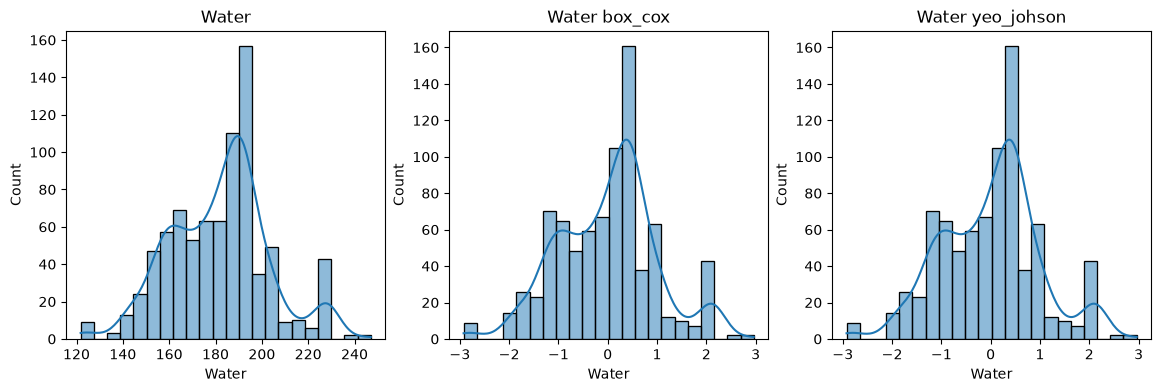

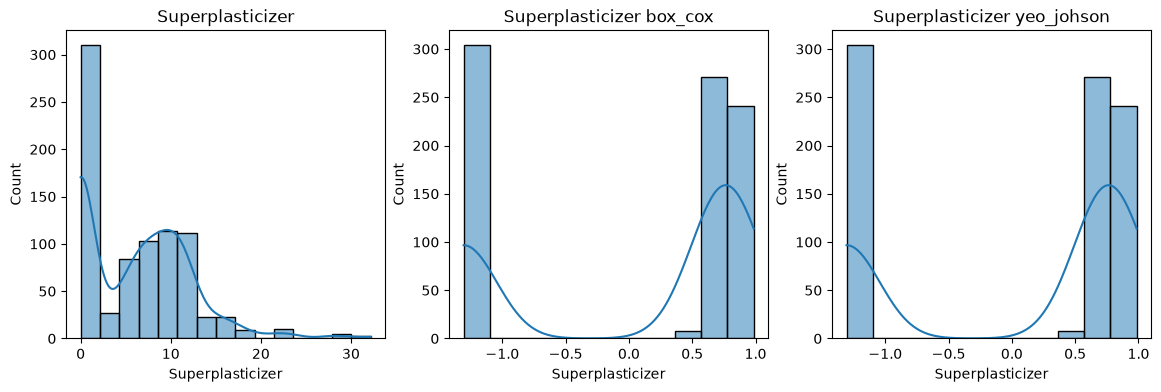

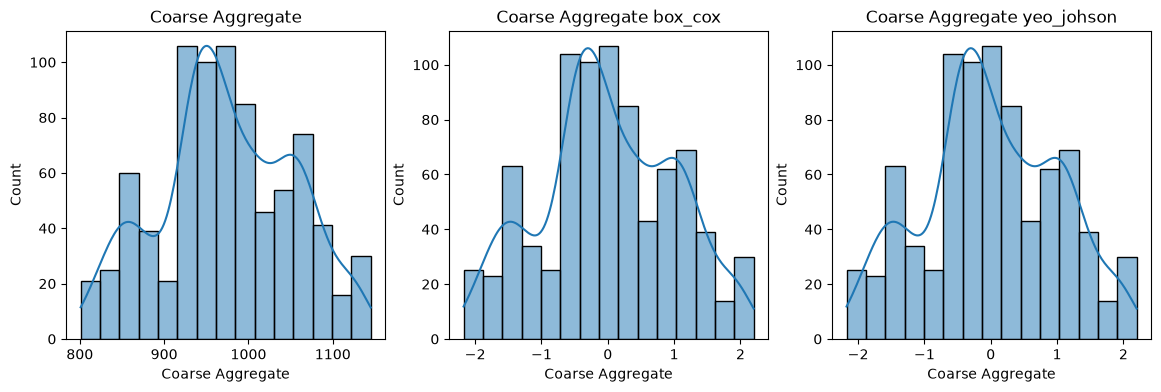

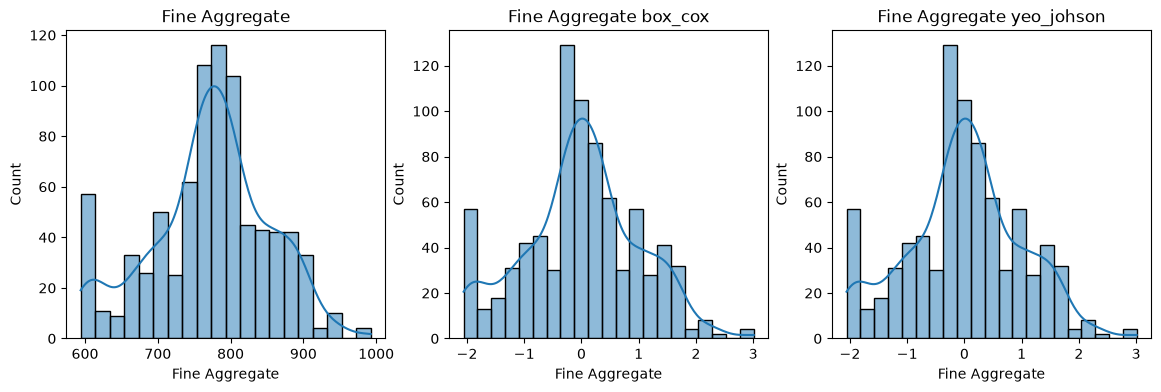

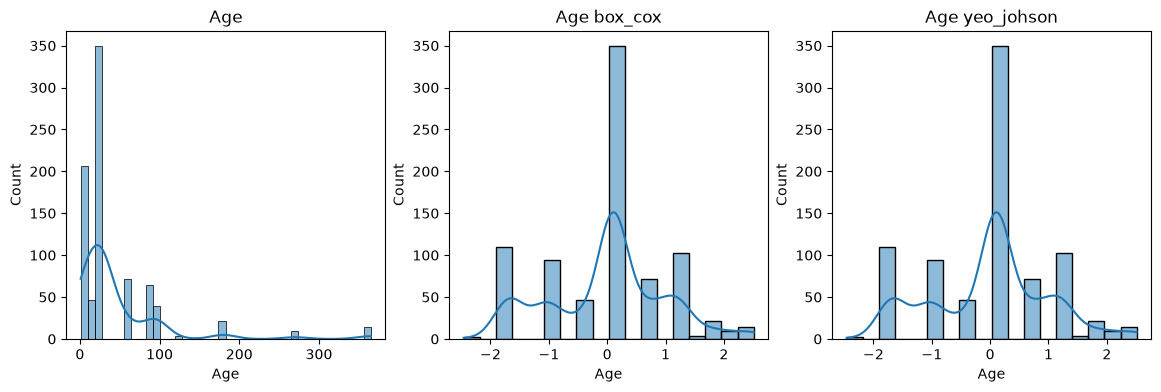

In [34]:
for col in X_train_transformed_ds.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(131)
    sns.histplot(X_train[col],kde=True)
    plt.title(col)
    
    plt.subplot(132)
    sns.histplot(X_train_transformed_ds[col],kde=True)
    plt.title(col+" box_cox")

    plt.subplot(133)
    sns.histplot(X_train_transformed_ds[col],kde=True)
    plt.title(col+" yeo_johson")
    
    plt.show()

In [35]:
pd.DataFrame({"Col": X_train.columns,"box_cox_lambda": pt.lambdas_,"Yeo_Johnson_lambda":pt1.lambdas_})

,Col,box_cox_lambda,Yeo_Johnson_lambda
0,Cement,0.177025,0.169544
1,Blast Furnace Slag,0.017671,0.016633
2,Fly Ash,-0.025976,-0.136480
3,Water,0.772682,0.808438
4,Superplasticizer,0.064135,0.264160
5,Coarse Aggregate,1.129813,1.129395
6,Fine Aggregate,1.782018,1.830764
7,Age,0.066631,0.001771
